# A Beginner-Friendly Multimodal Mixture of Experts (MoE)

**Project:** route an image + natural-language instruction to one of two YOLO experts:

- **Expert 0 — Classification:** predicts the pet breed using a YOLO classification model.
- **Expert 1 — Segmentation:** predicts a pixel mask using a YOLO segmentation model.
- **Gate / router:** a small trainable network that receives frozen CLIP image and text features and chooses the expert.

This notebook uses the **Oxford-IIIT Pet** dataset as a learning example. It trains the router and prepares/fine-tunes the two experts. The final inference wrapper is separate from training, so it can be used in another Python script.

> **Important design note:** this is a *hard-routing* MoE. The gate selects one expert per input; it does not blend the experts' predictions. The YOLO models are independent specialist models, while the router learns which one to call. The routing labels in this starter project come from the task requested in the prompt. This is a supervised task router, not yet a learned quality-based router.

## Suggested learning path

1. Install dependencies and configure paths.
2. Build and inspect the multimodal routing dataset.
3. Train and evaluate the CLIP-based gate.
4. Export the dataset into Ultralytics formats and train both YOLO experts.
5. Assemble the MoE, run predictions, and save portable checkpoints.
6. Load the saved checkpoints in a fresh Python process.

The notebook is intentionally kept modular. Run cells from top to bottom, and skip the YOLO fine-tuning cell if you already have suitable expert weights.

## 1. Environment, operating system and compute device

This notebook is designed to run on **macOS, Windows, Linux, and Google Colab**. The model code is shared across platforms; only installation, storage paths, and hardware selection differ.

### Recommended setup

- **Google Colab:** choose a GPU runtime in *Runtime → Change runtime type*. The notebook can optionally mount Google Drive.
- **Windows / Linux:** use a Python 3.10 or 3.11 virtual environment, then run the install cell below.
- **macOS:** Apple Silicon can use PyTorch's **MPS** backend. Intel Macs generally use CPU.
- **CUDA:** NVIDIA GPU acceleration requires a PyTorch build compatible with the CUDA version installed on your machine. If the default install does not detect CUDA, install the matching PyTorch build from the official PyTorch installation selector.

The setup cell detects Colab and selects CUDA, Apple MPS, or CPU automatically. It also uses conservative DataLoader settings that work reliably in notebooks and on Windows.

> **Important:** run the installation cell once, then restart the notebook kernel if it upgraded PyTorch. Re-run the notebook from the first cell after restarting.


In [1]:
# Install the project dependencies in the active notebook environment.
# For CUDA-specific PyTorch builds, see https://pytorch.org/get-started/locally/
%pip install -q open_clip_torch ultralytics opencv-python-headless torchvision matplotlib pillow

import os
import sys
import random
import json
import shutil
import platform
from pathlib import Path

import numpy as np
import torch

# Detect whether this notebook is running in Google Colab.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Select the best available PyTorch device.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

# Configure storage paths. Colab users may mount Drive for persistent artifacts.
if IN_COLAB:
    from google.colab import drive
    MOUNT_GOOGLE_DRIVE = True  # Change to False to use temporary Colab storage.
    if MOUNT_GOOGLE_DRIVE:
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/yolo_moe_project")
    else:
        PROJECT_DIR = Path("/content/yolo_moe_project")
else:
    # By default, keep project files in a folder beside the notebook's working directory.
    PROJECT_DIR = Path.cwd() / "yolo_moe_project"

DATA_DIR = PROJECT_DIR / "data"
RUNS_DIR = PROJECT_DIR / "runs"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

for folder in (PROJECT_DIR, DATA_DIR, RUNS_DIR, ARTIFACT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Conservative settings improve compatibility, especially on Windows notebooks.
# Increase NUM_WORKERS on Linux/Colab only if your environment benefits from it.
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

def get_ultralytics_device(device: torch.device):
    """Translate a PyTorch device into an Ultralytics-compatible device value.

    Input: torch.device such as cuda, mps, or cpu.
    Output: '0' for the first CUDA GPU, 'mps' for Apple Silicon, or 'cpu'.
    """
    if device.type == "cuda":
        return 0
    if device.type == "mps":
        return "mps"
    return "cpu"

YOLO_DEVICE = get_ultralytics_device(DEVICE)

print("Operating system:", platform.platform())
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Running in Colab:", IN_COLAB)
print("Selected device:", DEVICE)
print("Ultralytics device:", YOLO_DEVICE)
print("Project directory:", PROJECT_DIR)


Note: you may need to restart the kernel to use updated packages.
Operating system: macOS-26.5.2-arm64-arm-64bit-Mach-O
Python: 3.13.18
PyTorch: 2.15.0
Running in Colab: False
Selected device: mps
Ultralytics device: mps
Project directory: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project


### Device-specific notes

| Platform | Expected device | Notes |
|---|---|---|
| Google Colab with GPU | `cuda` | Best option for training both YOLO experts. |
| Linux / Windows with NVIDIA GPU | `cuda` | Install the matching CUDA-enabled PyTorch build. |
| Apple Silicon Mac | `mps` when supported | Router and YOLO inference/training may have operator or version limitations. If an operation fails on MPS, switch to CPU for that step. |
| Intel Mac / no supported GPU | `cpu` | Works for learning and small tests, but training will be slow. |

The notebook prints the selected device near the top. If you want to force CPU for debugging, replace the automatic device-selection block with `DEVICE = torch.device("cpu")`. To force MPS, use `DEVICE = torch.device("mps")` only when `torch.backends.mps.is_available()` is true.

For a first run on a laptop, consider reducing the YOLO training `batch` to `4` or `8` and `epochs` to `2` to validate the pipeline before a longer training run.

## 2. Dataset and routing labels

Each Oxford-IIIT Pet image has a breed/category label and a segmentation trimap. For router training, each image is represented twice:
- once with a classification instruction and target expert `0`;
- once with a segmentation instruction and target expert `1`.

This deliberately teaches the gate the basic behavior: **read the requested task, consider the image, and dispatch to the corresponding expert**. Since the task is explicitly stated in the prompt, the text signal will naturally be very informative. Later, you can add ambiguous or paraphrased prompts and evaluate whether the router generalizes.

The original Oxford trimap uses `1 = pet`, `2 = background`, `3 = boundary`. We preserve those values in the dataset. When exporting YOLO segmentation labels, we treat pet + boundary as foreground by default.

In [2]:
from typing import Dict, List, Tuple, Optional, Any
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image

EXPERT_CLS = 0
EXPERT_SEG = 1
EXPERT_NAMES = {EXPERT_CLS: "classification", EXPERT_SEG: "segmentation"}

CLASSIFICATION_PROMPTS = [
    "Classify the pet breed in this image.",
    "Identify the breed of the animal shown.",
    "What pet breed is visible in this picture?",
    "Return the breed category for this pet.",
]
SEGMENTATION_PROMPTS = [
    "Segment the pet from the background.",
    "Create a pixel mask around the animal.",
    "Outline the pet and separate it from the background.",
    "Return a segmentation mask for the animal.",
]

class PetMoEDataset(Dataset):
    """Create image/instruction examples with the correct expert-routing target.

    Why this class exists:
        The gate needs supervised examples that pair a visual input and a text
        instruction with the expert that should handle the task.

    Inputs:
        root: directory used by torchvision to store Oxford-IIIT Pet.
        split: 'trainval' or 'test'.
        image_size: square (height, width) used by the router.
        pair_tasks: if True, include both tasks for every image.

    Outputs:
        A dictionary containing:
            image: float tensor [3, H, W] in [0, 1].
            prompt: instruction string.
            expert_id: scalar long tensor (0=classification, 1=segmentation).
            class_label: scalar long tensor (breed index, or -1 for segmentation).
            mask: long tensor [H, W] containing Oxford trimap values, or None.
    """
    def __init__(self, root: str, split: str = "trainval", download: bool = True,
                 image_size: int = 224, pair_tasks: bool = True, seed: int = 42):
        self.base = datasets.OxfordIIITPet(
            root=root, split=split,
            target_types=["category", "segmentation"], download=download
        )
        self.classes = list(self.base.classes)
        self.image_size = image_size
        self.pair_tasks = pair_tasks
        self.rng = random.Random(seed)
        self.samples = []
        for image_idx in range(len(self.base)):
            if pair_tasks:
                self.samples.extend([(image_idx, EXPERT_CLS), (image_idx, EXPERT_SEG)])
            else:
                self.samples.append((image_idx, EXPERT_CLS if image_idx % 2 == 0 else EXPERT_SEG))

    def __len__(self):
        return len(self.samples)

    def _prompt(self, expert_id: int) -> str:
        """Choose a natural-language instruction matching the target expert.

        Input: expert_id, either 0 (classification) or 1 (segmentation).
        Output: one prompt string. Prompt variation reduces template memorization.
        """
        pool = CLASSIFICATION_PROMPTS if expert_id == EXPERT_CLS else SEGMENTATION_PROMPTS
        return self.rng.choice(pool)

    def __getitem__(self, index: int) -> Dict[str, Any]:
        """Load and transform one image/task pair.

        Input: integer dataset index.
        Output: dictionary described in the class docstring. Images are RGB;
        masks retain their original 1/2/3 trimap labels for correct interpretation.
        """
        base_idx, expert_id = self.samples[index]
        image, (category_id, mask) = self.base[base_idx]
        image = image.convert("RGB").resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        image_np = np.asarray(image, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1).contiguous()

        mask_image = mask.resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
        mask_tensor = torch.from_numpy(np.asarray(mask_image, dtype=np.int64).copy())

        breed_idx = int(category_id) - 1  # torchvision category IDs are 1-based for this dataset
        return {
            "image": image_tensor,
            "prompt": self._prompt(expert_id),
            "expert_id": torch.tensor(expert_id, dtype=torch.long),
            "class_label": torch.tensor(breed_idx if expert_id == EXPERT_CLS else -1, dtype=torch.long),
            "mask": mask_tensor if expert_id == EXPERT_SEG else None,
        }

def collate_router_batch(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Batch variable text strings and optional masks safely.

    Inputs: list of dataset samples.
    Outputs: stacked image/label tensors, a list of prompt strings, and a list
    of optional masks. Keeping masks as a list avoids trying to stack None values.
    """
    return {
        "images": torch.stack([x["image"] for x in batch]),
        "prompts": [x["prompt"] for x in batch],
        "expert_ids": torch.stack([x["expert_id"] for x in batch]),
        "class_labels": torch.stack([x["class_label"] for x in batch]),
        "masks": [x["mask"] for x in batch],
    }

train_ds = PetMoEDataset(str(DATA_DIR), split="trainval", seed=SEED)
val_ds = PetMoEDataset(str(DATA_DIR), split="test", seed=SEED + 1)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=NUM_WORKERS,
                          collate_fn=collate_router_batch, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=NUM_WORKERS,
                        collate_fn=collate_router_batch, pin_memory=PIN_MEMORY)

print(f"Train images: {len(train_ds.base)} | routing examples: {len(train_ds)}")
print(f"Validation images: {len(val_ds.base)} | routing examples: {len(val_ds)}")
print("Expert IDs:", EXPERT_NAMES)
sample = train_ds[0]
print("Image shape:", tuple(sample["image"].shape), "| prompt:", sample["prompt"],
      "| expert:", EXPERT_NAMES[int(sample["expert_id"])])

100%|██████████| 792M/792M [19:27<00:00, 678kB/s]  
100%|██████████| 19.2M/19.2M [00:31<00:00, 613kB/s] 


Train images: 3680 | routing examples: 7360
Validation images: 3669 | routing examples: 7338
Expert IDs: {0: 'classification', 1: 'segmentation'}
Image shape: (3, 224, 224) | prompt: Classify the pet breed in this image. | expert: classification


## 3. CLIP multimodal gate

CLIP maps images and text into a shared embedding space. We freeze CLIP to keep this first project manageable and train only a small MLP gate.

The gate receives three feature groups:
1. image embedding;
2. text embedding;
3. element-wise image/text interaction.

It returns two logits and routing probabilities. During inference, `argmax` selects one YOLO expert. Keeping the feature extractor frozen makes training lighter and reduces the number of moving parts while learning the MoE concept.

In [3]:
import open_clip
import torch.nn as nn
import torch.nn.functional as F

class CLIPMoERouter(nn.Module):
    """Frozen CLIP encoder plus a trainable two-expert routing network.

    Why it is relevant:
        It is the MoE gate. It converts the image and instruction into a
        probability distribution over the available specialist models.

    Inputs:
        images: float tensor [B, 3, H, W], RGB in [0, 1].
        prompts: list[str] of length B.
    Outputs:
        dict with logits [B, 2], probs [B, 2], and selected_expert [B].
    """
    def __init__(self, clip_model_name="ViT-B-32",
                 clip_pretrained="laion2b_s34b_b79k", hidden_dim=256, dropout=0.1):
        super().__init__()
        self.clip_model_name = clip_model_name
        self.clip_pretrained = clip_pretrained
        self.clip_model, _, _ = open_clip.create_model_and_transforms(
            model_name=clip_model_name, pretrained=clip_pretrained
        )
        self.tokenizer = open_clip.get_tokenizer(clip_model_name)
        self.register_buffer("clip_mean", torch.tensor(
            [0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1))
        self.register_buffer("clip_std", torch.tensor(
            [0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1))

        for parameter in self.clip_model.parameters():
            parameter.requires_grad = False
        self.clip_model.eval()

        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feature_dim = self.clip_model.encode_image(
                (dummy - self.clip_mean) / self.clip_std
            ).shape[-1]

        self.gate = nn.Sequential(
            nn.Linear(feature_dim * 3, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 2),
        )

    def train(self, mode: bool = True):
        """Set the trainable gate mode while keeping frozen CLIP in eval mode.

        Input: standard PyTorch training-mode boolean.
        Output: self. This prevents CLIP dropout/batch-norm behavior changing
        while the small gate is being optimized.
        """
        super().train(mode)
        self.clip_model.eval()
        return self

    def encode_inputs(self, images: torch.Tensor, prompts: List[str]):
        """Encode a batch of images and prompts with frozen CLIP.

        Inputs: images [B,3,H,W] in [0,1], prompts list of B strings.
        Outputs: L2-normalized image and text embeddings, each [B,D].
        """
        device = images.device
        images = (images - self.clip_mean.to(device)) / self.clip_std.to(device)
        tokens = self.tokenizer(prompts).to(device)
        with torch.no_grad():
            image_features = self.clip_model.encode_image(images)
            text_features = self.clip_model.encode_text(tokens)
        return F.normalize(image_features.float(), dim=-1), F.normalize(text_features.float(), dim=-1)

    def forward(self, images: torch.Tensor, prompts: List[str]):
        """Predict routing logits/probabilities for an image-text batch.

        Inputs: images [B,3,H,W] and B prompt strings.
        Outputs: dict of logits, probabilities, and argmax expert IDs.
        """
        image_features, text_features = self.encode_inputs(images, prompts)
        fused = torch.cat((image_features, text_features,
                           image_features * text_features), dim=-1)
        logits = self.gate(fused)
        probs = torch.softmax(logits, dim=-1)
        return {"logits": logits, "probs": probs, "selected_expert": probs.argmax(dim=-1)}

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Train and evaluate the gate

We use cross-entropy because each training example has one correct expert. Validation accuracy measures whether the gate chooses the requested task. The best checkpoint is saved separately from the YOLO experts.

A caveat for this starter dataset: since prompts explicitly say “classify” or “segment”, high routing accuracy mostly demonstrates prompt-conditioned dispatch. It does **not** prove that the router has learned when one expert is more suitable based on visual difficulty or model confidence.

In [4]:
def run_router_epoch(model, loader, optimizer=None, device=DEVICE):
    """Run one training or validation epoch for the routing network.

    Inputs:
        model: CLIPMoERouter.
        loader: batches from collate_router_batch.
        optimizer: optimizer for training; None means evaluation only.
        device: torch device.
    Outputs:
        dictionary with mean cross-entropy loss and routing accuracy.
    """
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total = 0.0, 0, 0
    for batch in loader:
        images = batch["images"].to(device, non_blocking=True)
        targets = batch["expert_ids"].to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            output = model(images, batch["prompts"])
            loss = F.cross_entropy(output["logits"], targets)
            if training:
                loss.backward()
                optimizer.step()
        count = targets.size(0)
        total_loss += loss.item() * count
        total_correct += (output["selected_expert"] == targets).sum().item()
        total += count
    return {"loss": total_loss / max(total, 1),
            "accuracy": total_correct / max(total, 1)}

router = CLIPMoERouter().to(DEVICE)
optimizer = torch.optim.AdamW(router.gate.parameters(), lr=1e-3, weight_decay=1e-4)
ROUTER_PATH = ARTIFACT_DIR / "router.pt"
best_val_accuracy = -1.0
EPOCHS_ROUTER = 5

for epoch in range(1, EPOCHS_ROUTER + 1):
    train_metrics = run_router_epoch(router, train_loader, optimizer, DEVICE)
    val_metrics = run_router_epoch(router, val_loader, None, DEVICE)
    print(f"Epoch {epoch:02d}/{EPOCHS_ROUTER} | "
          f"train loss {train_metrics['loss']:.4f}, acc {train_metrics['accuracy']:.3f} | "
          f"val loss {val_metrics['loss']:.4f}, acc {val_metrics['accuracy']:.3f}")
    if val_metrics["accuracy"] > best_val_accuracy:
        best_val_accuracy = val_metrics["accuracy"]
        torch.save({
            "model_state_dict": router.state_dict(),
            "clip_model_name": router.clip_model_name,
            "clip_pretrained": router.clip_pretrained,
            "best_val_accuracy": best_val_accuracy,
            "num_experts": 2,
            "expert_names": EXPERT_NAMES,
        }, ROUTER_PATH)

print("Best router checkpoint:", ROUTER_PATH)

Epoch 01/5 | train loss 0.0626, acc 0.991 | val loss 0.0005, acc 1.000
Epoch 02/5 | train loss 0.0003, acc 1.000 | val loss 0.0002, acc 1.000
Epoch 03/5 | train loss 0.0001, acc 1.000 | val loss 0.0001, acc 1.000
Epoch 04/5 | train loss 0.0001, acc 1.000 | val loss 0.0000, acc 1.000
Epoch 05/5 | train loss 0.0000, acc 1.000 | val loss 0.0000, acc 1.000
Best router checkpoint: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/router.pt


## 5. Export data for the two YOLO experts

Ultralytics expects different layouts for classification and segmentation:
- Classification: `train/<class_name>/image.jpg` and `val/<class_name>/image.jpg`.
- Segmentation: `train/images`, `train/labels`, `val/images`, `val/labels`, plus a dataset YAML.

The helper functions below rebuild the output folders to avoid mixing stale labels from earlier runs. Polygon export uses external contours; this is a practical baseline, though it does not preserve holes inside masks.

In [5]:
import cv2
from typing import Sequence

def prepare_yolo_classification_dataset(raw_root: str, output_dir: str):
    """Export Oxford-IIIT Pet into Ultralytics image-folder classification format.

    Inputs:
        raw_root: torchvision dataset root.
        output_dir: destination directory.
    Outputs:
        Path to directory containing train/<breed>/ and val/<breed>/.
    """
    output = Path(output_dir)
    if output.exists():
        shutil.rmtree(output)
    for yolo_split, source_split in (("train", "trainval"), ("val", "test")):
        dataset = datasets.OxfordIIITPet(root=raw_root, split=source_split,
                                         target_types=["category"], download=True)
        for class_name in dataset.classes:
            (output / yolo_split / class_name).mkdir(parents=True, exist_ok=True)
        for index, (image, category_id) in enumerate(dataset):
            class_name = dataset.classes[int(category_id) - 1]
            image.convert("RGB").save(output / yolo_split / class_name /
                                      f"pet_{index:05d}.jpg", quality=95)
    return output

def binary_mask_to_yolo_polygons(mask: np.ndarray, class_id: int = 0,
                                 min_area: float = 100.0) -> List[str]:
    """Convert a binary foreground mask into normalized YOLO polygon label lines.

    Inputs:
        mask: 2-D array; non-zero pixels are foreground.
        class_id: segmentation class index (this project has only 'pet', ID 0).
        min_area: ignore tiny contours to reduce noisy labels.
    Outputs:
        list of lines formatted as 'class x1 y1 x2 y2 ...', coordinates in [0,1].
    """
    height, width = mask.shape
    binary = (mask > 0).astype(np.uint8)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for contour in contours:
        if cv2.contourArea(contour) < min_area:
            continue
        perimeter = cv2.arcLength(contour, True)
        polygon = cv2.approxPolyDP(contour, 0.002 * perimeter, True).reshape(-1, 2)
        if len(polygon) < 3:
            continue
        coords = []
        for x, y in polygon:
            coords.extend([f"{np.clip(x / width, 0, 1):.6f}",
                           f"{np.clip(y / height, 0, 1):.6f}"])
        lines.append(str(class_id) + " " + " ".join(coords))
    return lines

def prepare_yolo_segmentation_dataset(raw_root: str, output_dir: str,
                                      include_boundary: bool = True):
    """Export Oxford trimaps as a one-class YOLO segmentation dataset.

    Inputs:
        raw_root: torchvision dataset root.
        output_dir: destination folder.
        include_boundary: include trimap value 3 with pet value 1 as foreground.
    Outputs:
        tuple (dataset directory Path, YAML config Path).
    """
    output = Path(output_dir)
    if output.exists():
        shutil.rmtree(output)
    for yolo_split, source_split in (("train", "trainval"), ("val", "test")):
        image_dir, label_dir = output / yolo_split / "images", output / yolo_split / "labels"
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        dataset = datasets.OxfordIIITPet(root=raw_root, split=source_split,
                                         target_types=["segmentation"], download=True)
        for index, (image, mask) in enumerate(dataset):
            trimap = np.asarray(mask, dtype=np.uint8)
            foreground = (trimap == 1) | ((trimap == 3) if include_boundary else False)
            lines = binary_mask_to_yolo_polygons(foreground.astype(np.uint8))
            if not lines:
                continue
            stem = f"pet_{index:05d}"
            image.convert("RGB").save(image_dir / f"{stem}.jpg", quality=95)
            (label_dir / f"{stem}.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
    yaml_path = output / "pets_seg.yaml"
    yaml_path.write_text(
        f"path: {output.resolve().as_posix()}\ntrain: train/images\nval: val/images\n"
        "names:\n  0: pet\n", encoding="utf-8"
    )
    return output, yaml_path

CLS_DATA_DIR = PROJECT_DIR / "yolo_cls_pets"
SEG_DATA_DIR = PROJECT_DIR / "yolo_seg_pets"

## 6. Fine-tune the YOLO experts (optional but recommended)

This cell trains a small YOLO classification model and a small YOLO segmentation model. The default epoch count is intentionally modest for a first experiment; increase it after checking validation metrics and GPU capacity.

The resulting `best.pt` files are copied into the stable artifact directory so inference does not depend on Ultralytics run-folder naming.

In [6]:
from ultralytics import YOLO

def train_yolo_experts(cls_data_dir: Path, seg_yaml: Path, runs_dir: Path,
                       artifact_dir: Path, epochs: int = 10,
                       cls_imgsz: int = 224, seg_imgsz: int = 640,
                       batch: int = 16):
    """Fine-tune separate YOLO classification and segmentation specialists.

    Inputs:
        cls_data_dir: classification dataset directory in Ultralytics format.
        seg_yaml: segmentation dataset YAML path.
        runs_dir: Ultralytics training output directory.
        artifact_dir: stable directory for copied best.pt files.
        epochs, image sizes, batch: training hyperparameters.
    Outputs:
        tuple (classification weights Path, segmentation weights Path).
    """
    runs_dir, artifact_dir = Path(runs_dir), Path(artifact_dir)
    cls_model = YOLO("yolo11n-cls.pt")
    cls_model.train(data=str(cls_data_dir), epochs=epochs, imgsz=cls_imgsz,
                    batch=batch, device=YOLO_DEVICE, project=str(runs_dir), name="pet_cls", exist_ok=True)
    cls_best = Path(cls_model.trainer.best)
    cls_out = artifact_dir / "classification_best.pt"
    shutil.copy2(cls_best, cls_out)

    seg_model = YOLO("yolo11n-seg.pt")
    seg_model.train(data=str(seg_yaml), epochs=epochs, imgsz=seg_imgsz,
                    batch=batch, device=YOLO_DEVICE, project=str(runs_dir), name="pet_seg", exist_ok=True)
    seg_best = Path(seg_model.trainer.best)
    seg_out = artifact_dir / "segmentation_best.pt"
    shutil.copy2(seg_best, seg_out)
    return cls_out, seg_out

# Run this block to create datasets and train experts.
# Comment it out if you already have expert .pt files.
cls_dataset_path = prepare_yolo_classification_dataset(str(DATA_DIR), str(CLS_DATA_DIR))
seg_dataset_path, seg_yaml_path = prepare_yolo_segmentation_dataset(str(DATA_DIR), str(SEG_DATA_DIR))
BEST_CLS_WEIGHTS, BEST_SEG_WEIGHTS = train_yolo_experts(
    cls_dataset_path, seg_yaml_path, RUNS_DIR, ARTIFACT_DIR,
    epochs=10, cls_imgsz=224, seg_imgsz=640, batch=16
)
print(BEST_CLS_WEIGHTS, BEST_SEG_WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/christy.manthara/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.15.0 MPS (Apple M1 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/yolo_cls_pets, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4,

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this 

       1/10       5.7G     0.8066      1.747     0.9458      1.468          0          9        640: 100% ━━━━━━━━━━━━ 230/230 1.7it/s 2:170.9ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 115/115 1.5it/s 1:180.5ss
                   all       3662       3767      0.818      0.837      0.877       0.52      0.738      0.714      0.704      0.302

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       2/10      6.79G      1.035      2.072      1.285       1.43          0         21        640: 0% ──────────── 0/230  2.2s

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this 

       2/10       6.7G     0.9996      1.882     0.7307      1.669          0          9        640: 100% ━━━━━━━━━━━━ 230/230 1.8it/s 2:080.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 115/115 1.7it/s 1:080.5ss
                   all       3662       3767      0.849      0.869       0.89      0.563      0.841      0.844      0.872      0.525

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/10      5.79G       1.02      1.898     0.5993      1.717          0         16        640: 0% ──────────── 0/230  1.5s

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this 

... (11 outputs left out)

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this 

       9/10      6.79G     0.5927      1.176     0.4093      1.249          0         10        640: 100% ━━━━━━━━━━━━ 230/230 1.9it/s 2:020.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 115/115 1.6it/s 1:100.5ss
                   all       3662       3767      0.972      0.955      0.976        0.8      0.976      0.952      0.974      0.783

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      10/10      5.79G     0.5951      1.077     0.4627      1.403          0         17        640: 0% ──────────── 0/230  1.9s

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this 

      10/10       6.7G     0.5305      1.064     0.3657      1.194          0          9        640: 100% ━━━━━━━━━━━━ 230/230 1.9it/s 2:030.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 115/115 1.8it/s 1:050.5ss
                   all       3662       3767      0.986       0.96       0.98      0.823      0.987      0.961       0.98      0.805

10 epochs completed in 0.550 hours.
Optimizer stripped from /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/runs/pet_seg/weights/last.pt, 6.0MB
Optimizer stripped from /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/runs/pet_seg/weights/best.pt, 6.0MB

Validating /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/runs/pet_seg/weights/best.pt...
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.15.0 MPS (Apple M1 Max)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 

## 7. Assemble the MoE and perform inference

The wrapper is intentionally a regular Python class rather than an `nn.Module`: Ultralytics' `YOLO` objects manage their own inference lifecycle and are not part of the router's PyTorch `state_dict`.

`predict()` accepts either a PIL image or a `[3,H,W]` float tensor in `[0,1]`, plus a prompt. It returns the selected expert, routing probabilities, and the raw Ultralytics result object. The raw result is useful for plotting masks or inspecting classification probabilities.

In [7]:
from PIL import Image

class YOLOMoE:
    """Hard-routing multimodal MoE that dispatches to one of two YOLO models.

    Why it is relevant:
        This is the deployable inference layer. It connects the learned gate
        with the two specialist YOLO checkpoints.

    Inputs to the constructor:
        router: loaded CLIPMoERouter.
        cls_weights_path: YOLO classification .pt path.
        seg_weights_path: YOLO segmentation .pt path.
        device: torch device used by the router and YOLO inference.

    Input to predict:
        image: PIL image or float tensor [3,H,W] in [0,1].
        prompt: natural-language task instruction.
        conf: YOLO confidence threshold.

    Output:
        dictionary with route name, expert ID, routing probabilities, and
        expert-specific prediction fields. 'result' contains Ultralytics Results.
    """
    def __init__(self, router, cls_weights_path: str, seg_weights_path: str,
                 device: torch.device = DEVICE):
        self.device = torch.device(device)
        self.router = router.to(self.device).eval()
        self.cls_expert = YOLO(str(cls_weights_path))
        self.seg_expert = YOLO(str(seg_weights_path))

    @staticmethod
    def _to_pil(image):
        """Normalize supported image input types to an RGB PIL image.

        Input: PIL image or float tensor [3,H,W] in [0,1].
        Output: RGB PIL image, suitable for Ultralytics prediction.
        """
        if isinstance(image, Image.Image):
            return image.convert("RGB")
        if not torch.is_tensor(image) or image.ndim != 3 or image.shape[0] != 3:
            raise TypeError("image must be a PIL image or a [3,H,W] torch tensor")
        array = (image.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        return Image.fromarray(array).convert("RGB")

    @torch.inference_mode()
    def predict(self, image, prompt: str, conf: float = 0.25):
        """Route one image/instruction pair and call only the selected expert.

        Inputs: image (PIL or tensor), prompt string, YOLO confidence threshold.
        Outputs: prediction dictionary; classification includes top class/confidence,
        segmentation includes instance count, and both include routing probabilities.
        """
        pil_image = self._to_pil(image)
        resized = pil_image.resize((224, 224), Image.Resampling.BILINEAR)
        arr = np.asarray(resized, dtype=np.float32) / 255.0
        router_image = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(self.device)

        route = self.router(router_image, [prompt])
        expert_id = int(route["selected_expert"].item())
        probabilities = route["probs"][0].detach().cpu().tolist()
        yolo_device = get_ultralytics_device(self.device)

        if expert_id == EXPERT_CLS:
            result = self.cls_expert.predict(pil_image, device=yolo_device, conf=conf, verbose=False)[0]
            if result.probs is None:
                raise RuntimeError("Classification expert returned no class probabilities.")
            top_id = int(result.probs.top1)
            return {
                "route": "classification", "expert_id": EXPERT_CLS,
                "routing_probs": {"classification": float(probabilities[0]),
                                  "segmentation": float(probabilities[1])},
                "top1_class_id": top_id, "top1_class_name": result.names[top_id],
                "top1_confidence": float(result.probs.top1conf.item()), "result": result,
            }

        result = self.seg_expert.predict(pil_image, device=yolo_device, conf=conf, verbose=False)[0]
        instance_count = 0 if result.masks is None else len(result.masks.data)
        return {
            "route": "segmentation", "expert_id": EXPERT_SEG,
            "routing_probs": {"classification": float(probabilities[0]),
                              "segmentation": float(probabilities[1])},
            "num_instances": instance_count, "result": result,
        }

def load_moe(artifact_dir: str, device: torch.device = DEVICE):
    """Reconstruct the router and both YOLO experts from saved .pt artifacts.

    Inputs:
        artifact_dir: folder containing router.pt, classification_best.pt,
                      and segmentation_best.pt.
        device: target torch device.
    Outputs:
        initialized YOLOMoE ready for predict().
    """
    artifact_dir = Path(artifact_dir)
    checkpoint = torch.load(artifact_dir / "router.pt", map_location=device)
    router_model = CLIPMoERouter(
        clip_model_name=checkpoint["clip_model_name"],
        clip_pretrained=checkpoint["clip_pretrained"],
    )
    router_model.load_state_dict(checkpoint["model_state_dict"])
    return YOLOMoE(router_model,
                   artifact_dir / "classification_best.pt",
                   artifact_dir / "segmentation_best.pt",
                   device=device)

print("Inference class and loader are ready.")

Inference class and loader are ready.


## 8. Save a portable model bundle

A PyTorch `.pt` file is used for each learned component. The router checkpoint includes its CLIP model identifier and weights; the two YOLO experts remain separate because Ultralytics loads them as independent models.

Keep the three `.pt` files together when moving the project to another machine. The CLIP backbone is reconstructed from its model name/pretrained identifier when loading, so the destination environment needs `open_clip_torch` and access to the corresponding pretrained weights (or a cached copy).

In [8]:
def save_moe_config(artifact_dir: str):
    """Write a small manifest describing the portable MoE artifact set.

    Input: artifact directory containing the three checkpoint files.
    Output: path to a JSON manifest with filenames and expert mapping.
    """
    folder = Path(artifact_dir)
    config = {
        "architecture": "hard_routing_multimodal_moe",
        "router_checkpoint": "router.pt",
        "experts": {
            "0": {"task": "classification", "checkpoint": "classification_best.pt"},
            "1": {"task": "segmentation", "checkpoint": "segmentation_best.pt"},
        },
        "router_inputs": "RGB image in [0,1] plus a natural-language prompt",
    }
    config_path = folder / "moe_config.json"
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
    return config_path

# Save/update the manifest once all three weights exist.
required_files = [ROUTER_PATH, ARTIFACT_DIR / "classification_best.pt",
                  ARTIFACT_DIR / "segmentation_best.pt"]
if all(path.exists() for path in required_files):
    print("Manifest:", save_moe_config(ARTIFACT_DIR))
    print("Portable artifacts:")
    for path in required_files:
        print(f" - {path} ({path.stat().st_size / 1e6:.1f} MB)")
else:
    print("Router checkpoint exists. Train or copy both YOLO expert weights into:")
    print(ARTIFACT_DIR)

Manifest: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/moe_config.json
Portable artifacts:
 - /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/router.pt (606.8 MB)
 - /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/classification_best.pt (3.3 MB)
 - /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/segmentation_best.pt (6.0 MB)


## 9. Inference example

Use a prompt that describes the desired task. The gate will select the corresponding expert. You can inspect `routing_probs` to see how confident the gate is.

If you trained the experts in this notebook, the paths should already be in `ARTIFACT_DIR`. If you use your own experts, copy their `.pt` files there using the expected filenames.

In [9]:
# Run after the router and both YOLO expert checkpoints are available.
if all(path.exists() for path in required_files):
    moe = load_moe(str(ARTIFACT_DIR), DEVICE)
    example = val_ds[0]
    for instruction in [
        "Please classify the breed of this pet.",
        "Please segment the pet from the background.",
    ]:
        prediction = moe.predict(example["image"], instruction)
        print(instruction)
        print({key: value for key, value in prediction.items() if key != "result"})
else:
    print("Skipping demo: one or more expert checkpoints are not present.")

Please classify the breed of this pet.
{'route': 'classification', 'expert_id': 0, 'routing_probs': {'classification': 0.9992603659629822, 'segmentation': 0.0007396346190944314}, 'top1_class_id': 36, 'top1_class_name': 'Yorkshire Terrier', 'top1_confidence': 0.9119749069213867}
Please segment the pet from the background.
{'route': 'segmentation', 'expert_id': 1, 'routing_probs': {'classification': 0.009014390408992767, 'segmentation': 0.990985631942749}, 'num_instances': 1}


## 10. Visualize a segmentation prediction

This helper overlays the predicted YOLO mask on the original image. The ground-truth Oxford trimap is displayed separately; pet pixels are value `1` and boundary pixels are value `3`.

For a segmentation request, the gate should select expert 1. If it selects classification, check the wording of the prompt and inspect the routing probabilities.

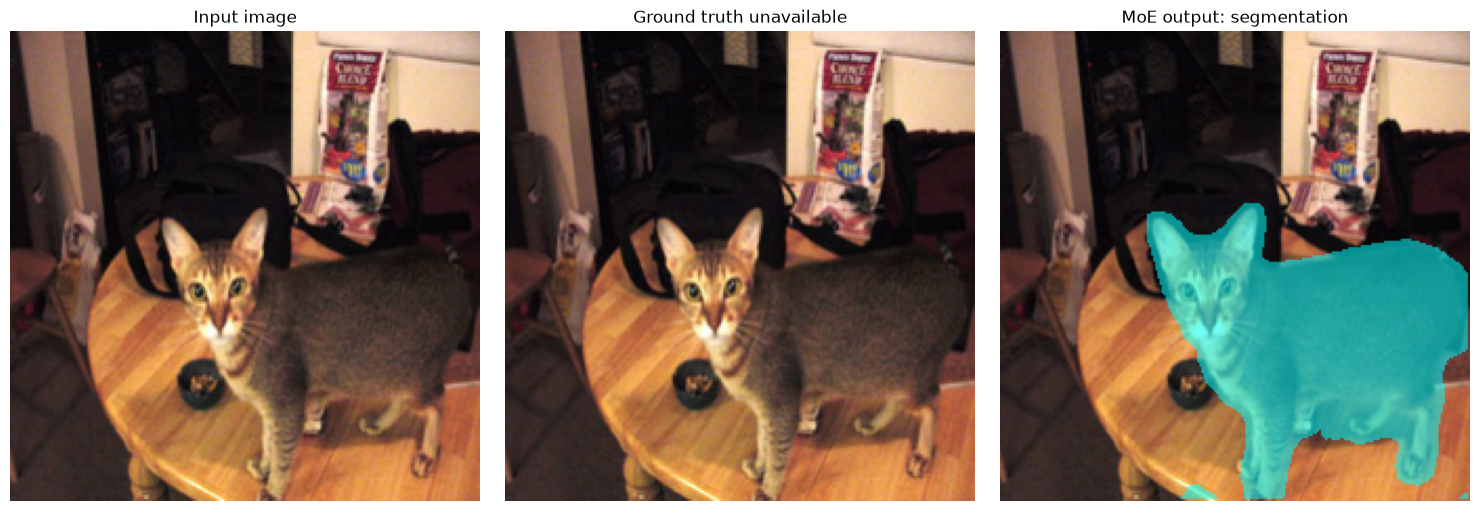

In [ ]:
import matplotlib.pyplot as plt

def plot_segmentation_prediction(image, prediction, ground_truth_mask=None):
    """Display the input, optional Oxford ground-truth mask, and YOLO prediction.

    Inputs:
        image: PIL image or [3,H,W] float tensor in [0,1].
        prediction: output dictionary from YOLOMoE.predict().
        ground_truth_mask: optional [H,W] Oxford trimap tensor/array.
    Outputs: matplotlib figure (displayed in notebook).
    """
    pil = YOLOMoE._to_pil(image)
    image_np = np.asarray(pil)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image_np)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    axes[1].imshow(image_np)
    if ground_truth_mask is not None:
        gt = ground_truth_mask.detach().cpu().numpy() if torch.is_tensor(ground_truth_mask) else np.asarray(ground_truth_mask)
        gt_pet = np.isin(gt, [1, 3])
        axes[1].imshow(np.ma.masked_where(~gt_pet, gt_pet), cmap="autumn", alpha=0.55)
        axes[1].set_title("Ground truth (pet + boundary)")
    else:
        axes[1].set_title("Ground truth unavailable")
    axes[1].axis("off")

    axes[2].imshow(image_np)
    result = prediction.get("result")
    if prediction.get("route") == "segmentation" and result is not None and result.masks is not None:
        masks = result.masks.data.detach().cpu().numpy()
        combined = masks.max(axis=0) > 0.5
        combined = cv2.resize(combined.astype(np.uint8), (image_np.shape[1], image_np.shape[0]),
                              interpolation=cv2.INTER_NEAREST)
        axes[2].imshow(np.ma.masked_where(combined == 0, combined), cmap="cool", alpha=0.55)
    axes[2].set_title(f"MoE output: {prediction['route']}")
    axes[2].axis("off")
    plt.tight_layout()
    plt.show()

# Example:
seg_instruction = "Segment the pet from the background."
seg_prediction = moe.predict(example["image"], seg_instruction)
plot_segmentation_prediction(example["image"], seg_prediction, example["mask"])

## 11. Using the model outside the notebook

After copying the `artifacts/` folder to another machine and installing compatible versions of `torch`, `open_clip_torch`, `ultralytics`, `Pillow`, and `numpy`, the deployment code can be reduced to:

```python
import torch
# Import CLIPMoERouter, YOLOMoE, and load_moe from your saved inference module.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
moe = load_moe("./artifacts", device)
prediction = moe.predict("./my_pet.jpg", "Segment the pet from the background.")
print({k: v for k, v in prediction.items() if k != "result"})
```

For a clean deployment, move the definitions of `CLIPMoERouter`, `YOLOMoE`, and `load_moe` into a Python file such as `moe_inference.py`. Do not rely on notebook variables like `train_ds` or `DEVICE` in that module; pass paths and devices explicitly.

## 12. Good next experiments

1. **Router robustness:** add more prompt paraphrases, indirect instructions, and typos; report a confusion matrix, not only accuracy.
2. **Better evaluation:** evaluate classification accuracy and segmentation mAP/IoU independently, in addition to routing accuracy.
3. **Confidence-aware routing:** run both experts on a validation subset and train the gate to select the expert with the better task-specific outcome. This is a more advanced objective than using the requested task as the label.
4. **Avoid leakage:** keep train/validation image splits separate (the current Oxford `trainval` and `test` split does this).
5. **Calibration:** inspect routing probabilities and consider a reject/uncertain option if neither expert is suitable.

This is a deliberately small first MoE. The central idea is the separation of concerns: **the gate decides where to send the request; the experts perform the task.**

### Device selection in a separate Python script

The standalone `load_moe()` function automatically selects CUDA, Apple MPS, or CPU when no device is supplied. You can override it:

```python
import torch
from moe_inference import load_moe

# Automatic selection:
moe = load_moe("./artifacts")

# Force CPU:
moe_cpu = load_moe("./artifacts", device=torch.device("cpu"))

# Force Apple Silicon MPS (only if available):
moe_mps = load_moe("./artifacts", device=torch.device("mps"))
```

On Windows, keep the `artifacts` folder and `moe_inference.py` in a known project directory, and use a virtual environment. The inference module does not mount Google Drive; copy/download the three checkpoint files to the local `artifacts` directory first.
